<a href="https://colab.research.google.com/github/KushagraPan/machine-learning-zoomcamp/blob/main/Homework_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Loading the Dataset
We fetch the CSV dataset from the remote GitHub repository using `pandas` and display the first few rows to inspect the structure of the lead scoring data.

### Loading Data
We load the course lead scoring dataset directly from the remote GitHub CSV URL into a pandas DataFrame and display the initial rows to inspect its structure.

In [34]:
import pandas as pd

url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df = pd.read_csv(url)

display(df.head())

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## 1. Data Cleaning and Imputation
Handling missing values across both categorical and numerical features.

### Handling Missing Values
We identify categorical and numerical columns. Missing categorical values are filled with the string `'NA'` and numerical missing values are filled with `0.0` to prevent computation errors during encoding or modeling.

### Imputing Missing Values
We separate columns into categorical and numerical types. Missing text/categorical values are filled with `'NA'` and missing numbers with `0.0` so the modeling algorithms can run successfully.

In [35]:
# Identify categorical and numerical columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns
numerical_cols = df.select_dtypes(include=['number']).columns

# Handle missing values as specified
df[categorical_cols] = df[categorical_cols].fillna('NA')
df[numerical_cols] = df[numerical_cols].fillna(0.0)

# Verify changes
display(df.isnull().sum())
display(df.head())

,0
lead_source,0
industry,0
employment_status,0
location,0
annual_income,0
number_of_courses_viewed,0
interaction_count,0
lead_score,0
converted,0


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NA,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## 2. Dataset Splitting
Splitting the raw dataset into training, validation, and test subsets.

### Train-Validation-Test Splitting
We split our initial data into three chunks: 60% for training the model, 20% for tuning validation metrics, and 20% reserved as an untouched test set.

In [36]:
#Split the data into 3 parts
from sklearn.model_selection import train_test_split
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1)

### Extracting Target Labels
We isolate and extract our target column (`converted`) into standalone ground truth arrays, then remove it from the training and validation feature sets.

In [37]:
y_train = df_train.converted.values
y_val = df_val.converted.values

del df_train['converted']
del df_val['converted']

## 3. Feature Importance Analysis
Evaluating individual numerical features against the target using ROC AUC scores.

### Feature Importance Evaluation
We compute the Area Under the ROC Curve (ROC AUC) for each individual numerical feature against the target to evaluate their predictive power.

In [38]:
from sklearn.metrics import roc_auc_score

features = [
    'lead_score',
    'number_of_courses_viewed',
    'interaction_count',
    'annual_income'
]

for feature in features:
    auc = roc_auc_score(y_train, df_train[feature])
    print(feature, auc)

lead_score 0.7882254810906102
number_of_courses_viewed 0.7229894623989618
interaction_count 0.7649203047563227
annual_income 0.6081977776250831


## 4. Feature Encoding
Transforming categorical features using a `DictVectorizer` to prepare them for modeling.

### Converting DataFrames to Dictionaries
We convert our training and validation pandas DataFrames into a list of dictionaries. This format is required by scikit-learn's `DictVectorizer` for encoding categorical variables.

In [39]:
#One hot encoding-convert dictionaries
train_dict = df_train.to_dict(orient='records')
val_dict = df_val.to_dict(orient='records')

### One-Hot Feature Encoding
We fit a `DictVectorizer` to translate categorical text categories into distinct, binary numerical columns (dummy variables) and transform the datasets.

In [40]:
from sklearn.feature_extraction import DictVectorizer
dv = DictVectorizer(sparse=False)
dv.fit(train_dict)
X_train = dv.transform(train_dict)
X_val = dv.transform(val_dict)



## 5. Model Training
Training a logistic regression classifier on the processed training set.

### Training the Logistic Regression Model
We initialize and fit a `LogisticRegression` classification model using the encoded training features and target labels.

In [41]:
#Trianing Logistic Regression
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(solver='liblinear', random_state=1, C = 1.0, max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, random_state=1, solver='liblinear')

## 6. Model Evaluation
Generating predictions and computing metrics like validation ROC AUC, as well as optimizing the decision threshold.

### Scoring Validation Probabilities
We use our trained model to estimate the probability of converting (`1`) for each instance in our validation dataset.

In [42]:
y_pred = model.predict_proba(X_val)[:, 1]

### Computing Overall Validation ROC AUC
We calculate the ROC AUC score on our validation set to measure the model's overall capability to distinguish between non-conversions and conversions.

In [43]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_val, y_pred)

print(auc.round(3))

0.732


### Plotting Precision-Recall Curves
We compute precision and recall across decision thresholds from `0.0` to `1.0` and plot them to visualize their trade-offs and locate where they cross.

0.97


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.p

<function matplotlib.pyplot.show(close=None, block=None)>

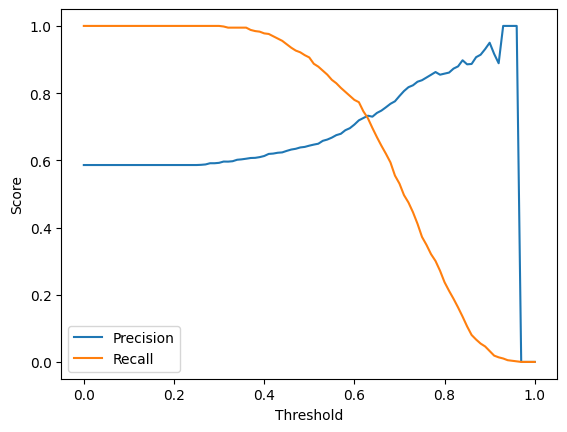

In [44]:
import numpy as np
from sklearn.metrics import precision_score, recall_score
import matplotlib.pyplot as plt


thresholds = np.arange(0.00, 1.01, 0.01)

best_threshold = None
best_diff = float('inf')
precisions = []
recalls = []

for threshold in thresholds:

    y_decision = y_pred >= threshold

    precision = precision_score(y_val, y_decision)
    recall = recall_score(y_val, y_decision)
    precisions.append(precision)
    recalls.append(recall)

    diff = abs(precision - recall)

    if diff < best_diff:
        best_diff = diff
        best_threshold = threshold

print(best_threshold)

plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.show

### Identifying Precision-Recall Intersection
We calculate the absolute difference between precision and recall at each threshold and print the top ten candidates to pinpoint where they are most closely balanced.

In [45]:
results = []

for threshold, precision, recall in zip(thresholds, precisions, recalls):
    diff = abs(precision - recall)
    results.append((diff, threshold, precision, recall))

results.sort()

for row in results[:10]:
    print(row)

(0.0, np.float64(0.97), 0.0, 0.0)
(0.0, np.float64(0.98), 0.0, 0.0)
(0.0, np.float64(0.99), 0.0, 0.0)
(0.0, np.float64(1.0), 0.0, 0.0)
(0.007502647993409384, np.float64(0.63), 0.7327586206896551, 0.7252559726962458)
(0.01982016713344592, np.float64(0.62), 0.7259136212624585, 0.7457337883959044)
(0.03362904259800836, np.float64(0.64), 0.7298747763864043, 0.6962457337883959)
(0.05398992361449695, np.float64(0.61), 0.719047619047619, 0.773037542662116)
(0.07207881442866637, np.float64(0.65), 0.7410207939508506, 0.6689419795221843)
(0.07352654150687599, np.float64(0.6), 0.7063369397217929, 0.7798634812286689)


### Optimizing the F1 Score
We calculate the harmonic mean of precision and recall ($F_1$ score) across all candidate thresholds to find the exact boundary that maximizes model accuracy.

In [46]:
#Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01. find the highest f1 with the threshold


thresholds = np.arange(0.00, 1.01, 0.01)

best_threshold = None
best_f1 = float('-inf')


for threshold in thresholds:
    y_decision = y_pred >= threshold

    precision = precision_score(y_val, y_decision, zero_division=0)
    recall = recall_score(y_val, y_decision, zero_division=0)

    if (precision + recall) > 0:
        f1 = 2 * precision * recall / (precision + recall)
    else:
        f1 = 0.0

    if f1 > best_f1:
        best_f1 = f1
        best_threshold = threshold


print("Best Threshold: ", best_threshold, " Best F1: ", best_f1)

Best Threshold:  0.41000000000000003  Best F1:  0.7576158940397352


### Baseline 5-Fold Cross-Validation
We perform a standard 5-fold cross-validation split on our combined training set to observe the overall robustness and variance of our baseline model.

In [51]:
from sklearn.model_selection import KFold



kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):

    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    train_dict = df_train.drop('converted', axis=1).to_dict(orient='records')
    val_dict = df_val.drop('converted', axis=1).to_dict(orient='records')

    dv = DictVectorizer(sparse=False)

    X_train = dv.fit_transform(train_dict)
    X_val = dv.transform(val_dict)

    model = LogisticRegression(
        solver='liblinear',
        C=1.0,
        max_iter=1000
    )

    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]

    auc = roc_auc_score(y_val, y_pred)

    scores.append(auc)

print(scores)
print(np.std(scores))



[np.float64(0.7305601027122453), np.float64(0.7295726148196622), np.float64(0.7363428071259397), np.float64(0.7412454717957564), np.float64(0.7209138590326581)]
0.006853233151022138


### Hyperparameter Tuning for Regularization (C)
We run 5-fold cross-validation over multiple values of the regularization strength parameter `C` to identify which setting minimizes overfitting and maximizes validation ROC AUC.

In [53]:
C_values = [0.000001, 0.001, 1]

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

for C in C_values:

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):

        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        train_dict = df_train.drop('converted', axis=1).to_dict(orient='records')
        val_dict = df_val.drop('converted', axis=1).to_dict(orient='records')

        dv = DictVectorizer(sparse=False)

        X_train = dv.fit_transform(train_dict)
        X_val = dv.transform(val_dict)

        model = LogisticRegression(
            solver='liblinear',
            C=C,
            max_iter=1000
        )

        model.fit(X_train, y_train)

        y_pred = model.predict_proba(X_val)[:, 1]

        auc = roc_auc_score(y_val, y_pred)

        scores.append(auc)

    mean_auc = np.mean(scores)
    std_auc = np.std(scores)

    print(
        C,
        round(mean_auc, 3),
        round(std_auc, 3)
    )

1e-06 0.617 0.019
0.001 0.749 0.01
1 0.732 0.007
